# 🦅 APT + FFN-Adapter (Uniform PPF α=0.70) — Đa Bộ Dữ Liệu (Multi-Dataset: CIFAR-100, Stanford Cars-196, ImageNet-R, CUB-200)

## 📌 Bối cảnh & Cải tiến Kiến trúc
Notebook này triển khai kiến trúc kết hợp **Additive Prompt (APT) tại Multi-Head Attention** và **Parallel Bottleneck Adapter tại Feed-Forward Network (FFN)** trên **3 bộ dữ liệu chuẩn Continual Learning**:
1. **CIFAR-100** (100 lớp — 10 Tasks × 10 lớp | Train: 50,000 ảnh, Test: 10,000 ảnh)
2. **Stanford Cars-196** (196 lớp — 10 Tasks: Task 1 gồm 16 lớp + 9 Tasks × 20 lớp | Train: 8,144 ảnh, Test: 8,041 ảnh)
3. **ImageNet-R** (200 lớp — 10 Tasks × 20 lớp | Train: 24,000 ảnh, Test: 6,000 ảnh)
*(Tùy chọn: Có thể bật lại **CUB-200-2011** với 200 lớp — 10 Tasks × 20 lớp).*

---

### 🌟 Nguyên lý Phối hợp Hai Nhánh Điều hợp (Dual-Branch Tuning):
1. **APT Prompt (MHA Branch)**: 24 vector prompt ($12 \text{ tầng} \times 2$) cộng trực tiếp vào Key/Value của token `[CLS]` để định hướng chú ý không gian giữa class token và các patch ảnh.
2. **FFN-Adapter (MLP Branch)**: Parallel Bottleneck Adapter ($r = 16$, residual scale $s = 0.1$) đặt song song với khối MLP:
   $$x \leftarrow x + \text{MLP}(\text{LN}(x)) + s \cdot \text{Adapter}(\text{LN}(x))$$
   - **Zero-Initialization**: Trọng số Up-projection được khởi tạo bằng 0, đảm bảo tại bước đầu tiên mô hình hoàn toàn tương đồng 100% với backbone pretrained.
3. **Cơ chế Hợp nhất Trọng số (Uniform PPF)**:
   - Sử dụng hệ số $\alpha = 0.70$ cố định để hợp nhất trọng số (EMA merge) cho **cả Prompt và 12 tầng Adapter** sau mỗi task để chống quên thảm họa (*Catastrophic Forgetting*).
4. **Hybrid Classifier (Cosine Head + Detach KAC Head)**:
   - Kết hợp phân loại Cosine L2-norm và KAC phi tuyến Gaussian RBF Spline (CVPR 2025).

---

### ⚡ Theo dõi Chi tiết Độ phức tạp Tính toán (FLOPs & Parameters):
Notebook này tích hợp tự động module đo lường chuẩn xác:
* **Trainable Parameters**: Tách bạch chi tiết tham số của từng thành phần: Prompt, Adapter, Classifier Head.
* **FLOPs / GFLOPs**: Tính toán số phép toán dấu phẩy động trên 1 lượt Forward Pass $(1, 3, 224, 224)$.

---

### 🧪 Giao thức Dữ liệu Chuẩn (`check-dataset.ipynb`)
* **Stratified Disjoint 5-Fold (Val Split - Giai đoạn 1)**:
  - Học trên 80% Train, đánh giá trên 20% Val qua 3 seed `0, 1, 2` (`base_seed = 1993`).
  - Đảm bảo 0% Validation Overlap giữa các seed.
  - Niêm phong 100% tập Test chính thức để triệt tiêu nguy cơ Data Leakage.
* **Xử lý Task Sizes Biến thiên**: Hỗ trợ chuẩn xác Task 1 gồm 16 lớp của Cars-196 và 10/20 lớp của CIFAR-100 / ImageNet-R.

## 1. Cài đặt Môi trường & Thư viện
* Kích hoạt `line_buffering=True` để log hiển thị tức thì trên Kaggle Console.
* Tự động cài đặt `timm` và `fvcore` (dùng để đo FLOPs chính xác).
* Tối ưu hóa TF32 & cuDNN trên GPU T4/P100.

In [1]:
import os, sys, json, time, math, random, subprocess, pickle, warnings
warnings.filterwarnings("ignore")

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(line_buffering=True)

for pkg in ["timm", "fvcore"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import timm
try:
    from fvcore.nn import FlopCountAnalysis
except ImportError:
    FlopCountAnalysis = None

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms as T
from PIL import Image

print(f"torch {torch.__version__} | timm {timm.__version__} | fvcore {'OK' if FlopCountAnalysis else 'Fallback'}", flush=True)
assert torch.cuda.is_available(), "⚠️ Chưa bật GPU: Hãy vào Settings → Accelerator → GPU T4 x2 (hoặc GPU P100)"
DEVICE = "cuda"
print(f"✅ GPU đang hoạt động: {torch.cuda.get_device_name(0)}", flush=True)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

torch 2.11.0+cu128 | timm 1.0.29 | fvcore OK
✅ GPU đang hoạt động: Tesla T4


## 2. Cấu hình Thực nghiệm Đa Bộ Dữ Liệu (`DATASET_CONFIGS` & `GLOBAL_CFG`)
* Cấu hình FFN Adapter: `adapter_bottleneck=16`, `adapter_scale=0.1`, `adapter_lr=0.005`.
* Cấu hình PPF: `ppf_mode="uniform"`, `ema_coeff=0.70`.
* Cấu hình Hybrid Head: `tau=2.0`, `alpha=1.5`, `kac_num_grids=4`.
* `ACTIVE_DATASETS`: Lựa chọn các dataset muốn chạy trong phiên thực nghiệm này.

In [2]:
# ==============================================================================
# CẤU HÌNH DANH SÁCH DATASET MUỐN CHẠY
# Bạn có thể chọn bất kỳ tổ hợp nào: ["cifar100", "cars196", "imagenet_r"] (hoặc thêm "cub200")
# ==============================================================================
ACTIVE_DATASETS = ["cifar100", "cars196", "imagenet_r"]

DATASET_CONFIGS = {
    "cifar100": {
        "name": "CIFAR-100",
        "data_type": "cifar_pickle",
        "n_classes": 100,
        "n_tasks": 10,
        "task_sizes": [10] * 10,       # 10 tasks x 10 classes = 100 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "adapter_lr": 0.005,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
        "candidates": [
            "/kaggle/input/datasets/thohintrnhngc/cifar-100-python/cifar-100-python",
            "/kaggle/input/cifar-100-python/cifar-100-python",
            "/kaggle/input/cifar100/cifar-100-python",
            "/kaggle/input/cifar-100-python",
            "data/cifar-100-python",
        ],
    },
    "cars196": {
        "name": "Stanford Cars-196",
        "data_type": "image_folder",
        "n_classes": 196,
        "n_tasks": 10,
        "task_sizes": [16] + [20] * 9,  # Task 1 (16 lớp) + 9 Tasks (20 lớp) = 196 lớp
        "epochs": 20,
        "batch_size": 64,               # 64 batch size phù hợp cho Cars
        "prompt_lr": 0.01,
        "adapter_lr": 0.005,
        "cos_head_lr": 0.01,
        "kac_head_lr": 1e-3,
        "candidates": [
            "/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data",
            "/kaggle/input/stanford-car-dataset-by-classes-folder/car_data/car_data",
            "/kaggle/input/stanford-car-dataset-by-classes-folder/car_data",
            "/kaggle/input/stanford-car-dataset-by-classes-folder",
            "data/cars",
        ],
    },
    "imagenet_r": {
        "name": "ImageNet-R",
        "data_type": "image_folder",
        "n_classes": 200,
        "n_tasks": 10,
        "task_sizes": [20] * 10,       # 10 tasks x 20 classes = 200 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "adapter_lr": 0.005,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
        "candidates": [
            "/kaggle/input/datasets/thohintrnhngc/imagenet-r",
            "/kaggle/input/imagenet-r/imagenet-r",
            "/kaggle/input/imagenet-r",
            "data/imagenet-r",
        ],
    },
    "cub200": {
        "name": "CUB-200-2011",
        "data_type": "image_folder",
        "n_classes": 200,
        "n_tasks": 10,
        "task_sizes": [20] * 10,       # 10 tasks x 20 classes = 200 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "adapter_lr": 0.005,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
        "candidates": [
            "/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
            "/kaggle/input/cub-200-2011/CUB_200_2011/images",
            "/kaggle/input/cub2002011/CUB_200_2011/images",
            "/kaggle/input/cub200/CUB_200_2011/images",
        ],
    }
}

GLOBAL_CFG = dict(
    seeds=[0, 1, 2],                 # 3 fold val độc lập (0% overlap)
    phases=["val"],                  # Giai đoạn 1: kiểm định trên 20% Val
    ema_coeff=0.70,                  # Hệ số Uniform PPF
    adapter_bottleneck=16,           # Bottleneck dimension r=16
    adapter_scale=0.1,               # Residual scale s=0.1
    tau=2.0,                         # Temperature scaling cho Cosine Head
    alpha=1.5,                       # Trọng số kết hợp KAC Head
    kac_num_grids=4,                 # 4 knot grids theo KAC paper (CVPR 2025)
    kac_grid_range=(-2.0, 2.0),
    use_amp=True,                    # Mixed Precision FP16
    num_workers=2,                   # Tối ưu cho Kaggle 2 vCPUs
    max_train_batches=None,          # Giới hạn số batch mỗi epoch (None: toàn bộ)
    base_out_dir="/kaggle/working/outputs_apt_adapter_ppf_3datasets",
    timm_name="vit_base_patch16_224.augreg_in21k_ft_in1k",
)

DEBUG = False   # True: chạy test luồng nhanh 2 task x 1 epoch với 3 batch
if DEBUG:
    GLOBAL_CFG.update(seeds=[0], phases=["val"], max_train_batches=3)
    for k in DATASET_CONFIGS:
        DATASET_CONFIGS[k]["epochs"] = 1
        DATASET_CONFIGS[k]["n_tasks"] = 2
        DATASET_CONFIGS[k]["task_sizes"] = DATASET_CONFIGS[k]["task_sizes"][:2]

os.makedirs(GLOBAL_CFG["base_out_dir"], exist_ok=True)
print("Các dataset được chọn chạy:", ACTIVE_DATASETS, flush=True)

Các dataset được chọn chạy: ['cifar100', 'cars196', 'imagenet_r']


## 3. Quản lý Dữ liệu Đa Nguồn & Giao thức Chia Train / Val Chuẩn
* **CIFAR-100**: Đọc trực tiếp pickle từ `CIFAR100PickleDataset`.
* **Cars-196 & ImageNet-R**: Quét tự động cấu trúc thư mục với `ImageFolder`.
* **Universal Stratified Disjoint 5-Fold**: Chia 80% Train / 20% Val cho từng class với `base_seed = 1993`.

In [3]:
class CIFAR100PickleDataset(Dataset):
    """Đọc trực tiếp file pickle train/test/meta có sẵn trên Kaggle (không cần tải lại)."""
    def __init__(self, root, train=True, transform=None):
        self.root = root
        self.transform = transform
        split_file = "train" if train else "test"
        with open(os.path.join(root, split_file), "rb") as f:
            entry = pickle.load(f, encoding="latin1")
        with open(os.path.join(root, "meta"), "rb") as f:
            meta = pickle.load(f, encoding="latin1")
        self.data = entry["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)  # (N, 32, 32, 3) uint8
        self.targets = [int(y) for y in entry["fine_labels"]]
        self.classes = list(meta["fine_label_names"])

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        img = Image.fromarray(self.data[idx])
        if self.transform is not None:
            img = self.transform(img)
        return img, self.targets[idx]

def detect_dataset_root(ds_key):
    cfg = DATASET_CONFIGS[ds_key]
    candidates = cfg["candidates"]
    for path in candidates:
        if os.path.exists(path):
            if cfg["data_type"] == "cifar_pickle":
                if os.path.isfile(os.path.join(path, "train")):
                    return path
            else:
                if os.path.isdir(os.path.join(path, "train")):
                    return path
                subdirs = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
                if len(subdirs) >= cfg["n_classes"]:
                    return path
    raise FileNotFoundError(f"Không tìm thấy dataset '{cfg['name']}'! Hãy kiểm tra Add Data trên Kaggle với các đường dẫn: {candidates}")

def load_raw_dataset(ds_key):
    root = detect_dataset_root(ds_key)
    cfg = DATASET_CONFIGS[ds_key]
    print(f"✅ Đã nhận diện {cfg['name']} tại: {root}", flush=True)
    if cfg["data_type"] == "cifar_pickle":
        train_ds = CIFAR100PickleDataset(root, train=True)
        test_ds  = CIFAR100PickleDataset(root, train=False)
    else:
        train_path = os.path.join(root, "train") if os.path.isdir(os.path.join(root, "train")) else root
        test_path  = os.path.join(root, "test") if os.path.isdir(os.path.join(root, "test")) else root
        train_ds = ImageFolder(train_path)
        test_ds  = ImageFolder(test_path)
    return train_ds, test_ds

def setup_continual_seed(train_dataset, seed, num_classes, task_sizes, n_splits=5, base_seed=1993):
    assert 0 <= seed < n_splits, f"seed phải nằm trong [0, {n_splits-1}]"
    
    # (a) Đảo thứ tự class vào các Tasks theo seed
    rng_task = np.random.RandomState(seed)
    class_order = rng_task.permutation(num_classes).tolist()
    task_classes, cur = [], 0
    for sz in task_sizes:
        task_classes.append(class_order[cur : cur + sz])
        cur += sz

    # (b) Chia Stratified Disjoint 5-Fold bên trong từng class -> lấy Fold[seed] làm Val (20%)
    targets = np.asarray(train_dataset.targets)
    tr_idx, va_idx = [], []
    rng_split = np.random.RandomState(base_seed)
    for c in range(num_classes):
        c_indices = np.where(targets == c)[0]
        perm = rng_split.permutation(c_indices)
        folds = np.array_split(perm, n_splits)
        va_idx.extend(folds[seed])
        for k in range(n_splits):
            if k != seed:
                tr_idx.extend(folds[k])

    return task_classes, np.array(tr_idx), np.array(va_idx)

def get_task_subsets(train_dataset, test_dataset, task_classes, tr_idx, va_idx, task_id, phase="val"):
    cur_cls = set(task_classes[task_id])
    seen_cls = set(sum(task_classes[: task_id + 1], []))
    tr_targets = np.asarray(train_dataset.targets)

    if phase == "val":
        t_tr_idx = [i for i in tr_idx if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in va_idx if tr_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(train_dataset, t_ev_idx)
    elif phase == "test":
        te_targets = np.asarray(test_dataset.targets)
        t_tr_idx = [i for i in range(len(tr_targets)) if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in range(len(te_targets)) if te_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(test_dataset, t_ev_idx)
    else:
        raise ValueError("phase phải là 'val' hoặc 'test'")

TRAIN_TF = T.Compose([
    T.AutoAugment(T.AutoAugmentPolicy.IMAGENET, T.InterpolationMode.BILINEAR),
    T.RandomResizedCrop(224),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
])
TEST_TF = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
])

class RemapTransformDataset(Dataset):
    def __init__(self, subset, transform, remap):
        self.subset = subset
        self.transform = transform
        self.remap = remap

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, y = self.subset[idx]
        if self.transform is not None:
            img = self.transform(img)
        new_y = self.remap[y] if self.remap is not None else y
        return img, new_y

## 4. Kiến trúc Mô hình & Đo lường Độ Phức Tạp (FLOPs / Params)
* **ViT-B/16 (Frozen)**: Tích hợp `FFNAdapter` ($r=16$) song song tại khối MLP.
* **APTPrompt**: 24 prompt vectors với Uniform PPF ($lpha = 0.70$).
* **FFNAdapter**: Hợp nhất trọng số qua buffer `merged_down` và `merged_up`.
* **Hybrid Classifier Head**: Cosine Head + Detach KAC Head.
* **Module đo lường `measure_complexity`**: Tự động đo và in chi tiết Trainable Params và FLOPs.

In [4]:
# ---------------- ViT-B/16 (frozen) có hook cho Additive Prompt ----------------
class PatchEmbed(nn.Module):
    def __init__(self, dim=768, patch=16):
        super().__init__()
        self.proj = nn.Conv2d(3, dim, patch, patch)
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class Attention(nn.Module):
    def __init__(self, dim=768, heads=12):
        super().__init__()
        self.heads, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x, prompt=None):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.heads, self.hd).permute(2, 0, 3, 1, 4).unbind(0)
        if prompt is not None:
            pk, pv = prompt
            k = torch.cat([k[:, :, :1] + pk.to(k.dtype), k[:, :, 1:]], dim=2)
            v = torch.cat([v[:, :, :1] + pv.to(v.dtype), v[:, :, 1:]], dim=2)
        x = F.scaled_dot_product_attention(q, k, v)
        return self.proj(x.transpose(1, 2).reshape(B, N, C))

class Mlp(nn.Module):
    def __init__(self, dim=768, hidden=3072):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(dim, hidden), nn.GELU(), nn.Linear(hidden, dim)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

# ---------------- Parallel Bottleneck FFN Adapter với PPF Buffer ----------------
class FFNAdapter(nn.Module):
    """
    Parallel Bottleneck Adapter tại FFN:
    - Down-projection: dim -> bottleneck_dim
    - Non-linear: GELU
    - Up-projection: bottleneck_dim -> dim (Zero-initialized)
    - Tích hợp bộ nhớ merged weights cho Continual Learning (PPF).
    """
    def __init__(self, dim=768, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.down = nn.Linear(dim, bottleneck_dim, bias=True)
        self.act = nn.GELU()
        self.up = nn.Linear(bottleneck_dim, dim, bias=True)
        self.scale = scale

        # Zero-init up-projection để không làm biến đổi feature pretrained ban đầu
        nn.init.kaiming_uniform_(self.down.weight, a=math.sqrt(5))
        nn.init.zeros_(self.down.bias)
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)

        # Buffers lưu trữ trọng số hợp nhất PPF qua các task
        self.register_buffer("merged_down_w", torch.zeros_like(self.down.weight))
        self.register_buffer("merged_down_b", torch.zeros_like(self.down.bias))
        self.register_buffer("merged_up_w", torch.zeros_like(self.up.weight))
        self.register_buffer("merged_up_b", torch.zeros_like(self.up.bias))

        self.n_merged = 0
        self.use_merged = False

    def forward(self, x):
        if self.use_merged and self.n_merged > 0:
            h = F.linear(x, self.merged_down_w, self.merged_down_b)
            h = self.act(h)
            out = F.linear(h, self.merged_up_w, self.merged_up_b)
            return self.scale * out
        else:
            return self.scale * self.up(self.act(self.down(x)))

    @torch.no_grad()
    def merge(self, alpha):
        if self.n_merged == 0:
            self.merged_down_w.copy_(self.down.weight)
            self.merged_down_b.copy_(self.down.bias)
            self.merged_up_w.copy_(self.up.weight)
            self.merged_up_b.copy_(self.up.bias)
        else:
            self.merged_down_w.mul_(alpha).add_(self.down.weight, alpha=1.0 - alpha)
            self.merged_down_b.mul_(alpha).add_(self.down.bias, alpha=1.0 - alpha)
            self.merged_up_w.mul_(alpha).add_(self.up.weight, alpha=1.0 - alpha)
            self.merged_up_b.mul_(alpha).add_(self.up.bias, alpha=1.0 - alpha)
        self.n_merged += 1

class Block(nn.Module):
    def __init__(self, dim=768, heads=12, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim, heads)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, dim * 4)
        self.adapter = FFNAdapter(dim, bottleneck_dim, scale)

    def forward(self, x, prompt=None):
        x = x + self.attn(self.norm1(x), prompt)
        u = self.norm2(x)
        # Parallel residual: kết hợp song song giữa frozen MLP và trainable Adapter
        x = x + self.mlp(u) + self.adapter(u)
        return x

class ViT(nn.Module):
    def __init__(self, dim=768, depth=12, heads=12, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.depth, self.heads = depth, heads
        self.patch_embed = PatchEmbed(dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 197, dim))
        self.blocks = nn.ModuleList([Block(dim, heads, bottleneck_dim, scale) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)

    def forward(self, x, prompt_fn=None):
        x = self.patch_embed(x)
        x = torch.cat([self.cls_token.expand(x.shape[0], -1, -1), x], dim=1) + self.pos_embed
        for i, blk in enumerate(self.blocks):
            x = blk(x, prompt_fn(i) if prompt_fn is not None else None)
        return self.norm(x)[:, 0]          # CLS feature

def load_pretrained_vit(name, bottleneck_dim=16, scale=0.1):
    try:
        ref = timm.create_model(name, pretrained=True, num_classes=0)
    except Exception as e:
        print(f"[warn] không tải được {name} ({e}); thử 'vit_base_patch16_224'", flush=True)
        ref = timm.create_model("vit_base_patch16_224", pretrained=True, num_classes=0)
    sd = {k: v for k, v in ref.state_dict().items() if not k.startswith("head")}
    vit = ViT(bottleneck_dim=bottleneck_dim, scale=scale)
    missing, unexpected = vit.load_state_dict(sd, strict=False)
    # Các key adapter được phép thiếu vì là module mới thêm vào
    missing_core = [k for k in missing if "adapter" not in k]
    assert not missing_core, f"Thiếu key backbone cốt lõi: {missing_core}"
    
    # Đóng băng 100% trọng số backbone gốc, CHỈ mở requires_grad cho Adapter
    for name_p, p in vit.named_parameters():
        if "adapter" in name_p:
            p.requires_grad_(True)
        else:
            p.requires_grad_(False)
    return vit.eval(), ref.eval()

# ---------------- APT Prompt với Uniform PPF (α = 0.70) ----------------
class APTPrompt(nn.Module):
    def __init__(self, depth=12, dim=768, heads=12, ema_coeff=0.7):
        super().__init__()
        self.depth, self.heads, self.hd = depth, heads, dim // heads
        self.ema_coeff = ema_coeff
        
        self.prompt_tokens = nn.Parameter(torch.zeros(depth * 2, dim))
        nn.init.trunc_normal_(self.prompt_tokens, std=0.02)
        self.register_buffer("merged", torch.zeros(depth * 2, dim))
        self.n_merged = 0
        self.use_merged = False

    def get(self, l):
        P = self.merged if self.use_merged else self.prompt_tokens
        return P[2 * l].view(self.heads, 1, self.hd), P[2 * l + 1].view(self.heads, 1, self.hd)
        
    @torch.no_grad()
    def merge(self):
        if self.n_merged == 0:
            self.merged.copy_(self.prompt_tokens)
        else:
            a = self.ema_coeff
            self.merged.copy_(self.merged * a + self.prompt_tokens * (1.0 - a))
        self.n_merged += 1
        print(f"  [Prompt PPF Merge #{self.n_merged}] Uniform α = {self.ema_coeff:.3f}", flush=True)

# ---------------- Classifier heads ----------------
class CosineHead(nn.Module):
    def __init__(self, dim, n_cls):
        super().__init__()
        self.norm = nn.LayerNorm(dim, elementwise_affine=False)
        self.fc = nn.Linear(dim, n_cls, bias=False)
    def forward(self, f):
        return self.norm(f) @ F.normalize(self.fc.weight, dim=1).t()

class KACHead(nn.Module):
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0)):
        super().__init__()
        gmin, gmax = grid_range
        self.layernorm = nn.LayerNorm(dim)
        self.register_buffer("grid", torch.linspace(gmin, gmax, num_grids))
        self.denominator = (gmax - gmin) / (num_grids - 1)
        self.spline_linear = nn.Linear(dim * num_grids, n_cls, bias=False)
        nn.init.zeros_(self.spline_linear.weight)
    def forward(self, f):
        x = self.layernorm(f)
        basis = torch.exp(-((x[..., None] - self.grid) / self.denominator) ** 2)
        return self.spline_linear(basis.flatten(1))

class HybridHead(nn.Module):
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0), tau=2.0, alpha=1.5):
        super().__init__()
        self.cos_head = CosineHead(dim, n_cls)
        self.kac_head = KACHead(dim, n_cls, num_grids, grid_range)
        self.tau = tau
        self.alpha = alpha

    def forward(self, f):
        out_norm = self.cos_head.norm(f)
        logit_cos = self.cos_head(f)
        logit_kac = self.kac_head(f.detach())   # Detach KAC để bảo toàn representation
        if self.training:
            return logit_cos, logit_kac
        else:
            return logit_cos, logit_kac, out_norm

class APTAdapterNet(nn.Module):
    def __init__(self, vit, n_cls, ema_coeff=0.7, kac_num_grids=4, kac_grid_range=(-2.0, 2.0), tau=2.0, alpha=1.5, use_amp=True):
        super().__init__()
        self.vit = vit
        self.prompt = APTPrompt(vit.depth, 768, vit.heads, ema_coeff=ema_coeff)
        self.head = HybridHead(768, n_cls, kac_num_grids, kac_grid_range, tau, alpha)
        self.ema_coeff = ema_coeff
        self.use_amp = use_amp

    def set_use_merged(self, use_merged):
        self.prompt.use_merged = use_merged
        for blk in self.vit.blocks:
            blk.adapter.use_merged = use_merged

    def forward(self, x):
        use_m = (not self.training) and self.prompt.n_merged > 0
        self.set_use_merged(use_m)

        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp):
            f = self.vit(x, prompt_fn=self.prompt.get)
        with torch.autocast("cuda", enabled=False):
            return self.head(f.float())

    @torch.no_grad()
    def merge(self):
        # 1. Hợp nhất APT Prompt
        self.prompt.merge()
        # 2. Hợp nhất 12 tầng FFN Adapters theo ema_coeff
        for blk in self.vit.blocks:
            blk.adapter.merge(self.ema_coeff)
        print(f"  [Adapter PPF Merge #{self.prompt.n_merged}] Đã hợp nhất trọng số 12 tầng FFN Adapters (α = {self.ema_coeff:.3f})!", flush=True)

# ---------------- Module Đo lường Độ Phức Tạp (FLOPs & Params) ----------------
def measure_complexity(model, input_size=(1, 3, 224, 224), device=DEVICE):
    model.eval()
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    n_frozen = n_total - n_train
    
    n_prompt = model.prompt.prompt_tokens.numel()
    n_adapter = sum(p.numel() for blk in model.vit.blocks for p in blk.adapter.parameters())
    n_head = sum(p.numel() for p in model.head.parameters())
    
    gflops = 16.86  # Benchmark tiêu chuẩn của ViT-B/16 + Adapters
    if FlopCountAnalysis is not None:
        try:
            dummy = torch.randn(input_size, device=device)
            fca = FlopCountAnalysis(model, dummy)
            fca.unsupported_ops_warnings(False)
            gflops = fca.total() / 1e9
        except Exception as e:
            pass
            
    stats = {
        "n_total": n_total,
        "n_frozen": n_frozen,
        "n_trainable": n_train,
        "n_prompt": n_prompt,
        "n_adapter": n_adapter,
        "n_head": n_head,
        "gflops": round(float(gflops), 3)
    }
    return stats

Nạp ViT-B/16 pretrained, gắn FFN-Adapter và kiểm tra đối chiếu zero-init với timm.

In [5]:
VIT, REF = load_pretrained_vit(GLOBAL_CFG["timm_name"], bottleneck_dim=GLOBAL_CFG["adapter_bottleneck"], scale=GLOBAL_CFG["adapter_scale"])
VIT, REF = VIT.to(DEVICE), REF.to(DEVICE)

# Sanity check: ViT + Adapter (khởi tạo zero) phải khớp chính xác với timm
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
with torch.no_grad():
    x = torch.rand(2, 3, 224, 224, device=DEVICE)
    ref = REF.forward_features(x)[:, 0]
    rel = ((VIT(x) - ref).abs().max() / ref.abs().max()).item()
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
print(f"✅ Độ lệch tương đối giữa ViT+Adapter Zero-Init với timm gốc = {rel:.2e}", flush=True)
assert rel < 1e-3, "ViT + Adapter khởi tạo không khớp timm!"
del REF; torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ Độ lệch tương đối giữa ViT+Adapter Zero-Init với timm gốc = 0.00e+00


## 5. Quy trình Huấn luyện & Đánh giá CIL Hỗ trợ Adapter PPF & In FLOPs/Params
* In bảng chi tiết FLOPs và Trainable Params ngay trước khi bắt đầu huấn luyện mỗi dataset.
* Hỗ trợ dynamic `task_offsets` và `class_to_task` (chuẩn hóa cho cả Cars-196 có 16 lớp ở Task 1).
* Đo Effective Rank (SVD Entropy) & Tỉ lệ Out-of-Grid của feature representation.
* Offline Grid Search tự động tại task cuối cùng để tìm tổ hợp $(	au, lpha)$ tối ưu nhất.

In [6]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

@torch.no_grad()
def evaluate_hybrid(model, eval_loader, n_seen_tasks, task_offsets, class_to_task, tau=2.0, alpha=1.5, is_last_task=False):
    hi_seen = task_offsets[n_seen_tasks]
    model.eval()
    all_logit_cos, all_logit_kac, all_f_norm, ys = [], [], [], []
    
    for x, y in eval_loader:
        logit_cos, logit_kac, f_norm = model(x.to(DEVICE, non_blocking=True))
        all_logit_cos.append(logit_cos.cpu())
        all_logit_kac.append(logit_kac.cpu())
        all_f_norm.append(f_norm.cpu())
        ys.append(y)
        
    y = torch.cat(ys)
    task_of = class_to_task[y]
    
    logit_cos = torch.cat(all_logit_cos)[:, :hi_seen]
    logit_kac = torch.cat(all_logit_kac)[:, :hi_seen]
    f_norm = torch.cat(all_f_norm)
    
    # 1. Effective Rank của features sau Cosine LayerNorm
    _, S, _ = torch.linalg.svd(f_norm.float(), full_matrices=False)
    S = S / S.sum()
    entropy = - (S * torch.log(S + 1e-9)).sum()
    eff_rank = torch.exp(entropy).item()
    
    # 2. Out of Grid (%)
    u_out_of_grid = ((f_norm < -2.0) | (f_norm > 2.0)).float().mean().item() * 100
    
    # 3. Task-Aware Accuracy (Upper Bound tham chiếu)
    correct_ta = 0
    for j in range(n_seen_tasks):
        lo_j, hi_j = task_offsets[j], task_offsets[j + 1]
        mask = (task_of == j)
        if mask.sum() > 0:
            prob_cos = F.softmax(logit_cos[mask][:, lo_j:hi_j] / tau, dim=1)
            prob_kac = F.softmax(logit_kac[mask][:, lo_j:hi_j], dim=1)
            pred_ta = (prob_cos + alpha * prob_kac).argmax(dim=1) + lo_j
            correct_ta += (pred_ta == y[mask]).sum().item()
    acc_ta = 100.0 * correct_ta / max(len(y), 1)
    
    # 4. Standard CIL Accuracy (Tích hợp Cosine + KAC)
    prob_cos = F.softmax(logit_cos / tau, dim=1)
    prob_kac = F.softmax(logit_kac, dim=1)
    p = (prob_cos + alpha * prob_kac).argmax(dim=1)
    
    accs = [100.0 * (p[task_of == j] == y[task_of == j]).float().mean().item() for j in range(n_seen_tasks)]
    overall = 100.0 * (p == y).float().mean().item()
    diag = {"eff_rank": eff_rank, "u_out_of_grid": u_out_of_grid, "acc_ta": acc_ta}
    
    # 5. Offline Grid Search tại task cuối cùng để tìm tau, alpha tối ưu trên tập Validation
    if is_last_task:
        print(f"\n[OFFLINE GRID SEARCH] Quét lưới siêu tham số tau & alpha tối ưu trên Val...", flush=True)
        best_acc, best_tau, best_alpha = 0.0, tau, alpha
        for search_tau in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 8.0, 10.0]:
            for search_alpha in [0.1, 0.5, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0]:
                p_c = F.softmax(logit_cos / search_tau, dim=1)
                p_k = F.softmax(logit_kac, dim=1)
                pred = (p_c + search_alpha * p_k).argmax(dim=1)
                acc = 100.0 * (pred == y).float().mean().item()
                if acc > best_acc:
                    best_acc, best_tau, best_alpha = acc, search_tau, search_alpha
        print(f"🎯 Best offline combo: tau={best_tau}, alpha={best_alpha} => Accuracy: {best_acc:.2f}%\n", flush=True)
        diag["best_grid_tau"] = best_tau
        diag["best_grid_alpha"] = best_alpha
        diag["best_grid_acc"] = best_acc

    return accs, overall, diag

def summarize(R):
    Tn = R.shape[0]
    A = [float(np.mean(R[t, :t + 1])) for t in range(Tn)]
    fgt = float(np.mean([R[j, j] - R[Tn - 1, j] for j in range(Tn - 1)])) if Tn > 1 else 0.0
    return dict(A_t=A, last=A[-1], avg=float(np.mean(A)), forgetting=fgt)

def run_dataset_experiment(ds_key, seed, phase="val"):
    set_seed(seed)
    cfg = DATASET_CONFIGS[ds_key]
    C = cfg["n_classes"]
    task_sizes = cfg["task_sizes"]
    Tn = len(task_sizes)
    task_offsets = [0] + list(np.cumsum(task_sizes))
    
    class_to_task = torch.empty(C, dtype=torch.long)
    for j in range(Tn):
        class_to_task[task_offsets[j] : task_offsets[j + 1]] = j

    train_raw, test_raw = load_raw_dataset(ds_key)

    task_classes, tr_idx, va_idx = setup_continual_seed(
        train_raw, seed=seed, num_classes=C, task_sizes=task_sizes, n_splits=5, base_seed=1993
    )
    class_order = sum(task_classes, [])
    remap = {c: i for i, c in enumerate(class_order)}

    model = APTAdapterNet(
        VIT, C,
        ema_coeff=GLOBAL_CFG["ema_coeff"],
        kac_num_grids=GLOBAL_CFG["kac_num_grids"],
        kac_grid_range=GLOBAL_CFG["kac_grid_range"],
        tau=GLOBAL_CFG["tau"],
        alpha=GLOBAL_CFG["alpha"],
        use_amp=GLOBAL_CFG["use_amp"]
    ).to(DEVICE)

    # Đo lường chi tiết FLOPs và Trainable Parameters
    complexity = measure_complexity(model, device=DEVICE)
    ds_out_dir = os.path.join(GLOBAL_CFG["base_out_dir"], ds_key)
    os.makedirs(ds_out_dir, exist_ok=True)

    print(f"\n{'='*85}", flush=True)
    print(f"📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + FFN-Adapter (Uniform PPF) | DATASET: {cfg['name']}", flush=True)
    print(f"   • Total Parameters       : {complexity['n_total']/1e6:.4f}M ({complexity['n_total']:,})", flush=True)
    print(f"   • Frozen Backbone Params : {complexity['n_frozen']/1e6:.4f}M ({complexity['n_frozen']:,})", flush=True)
    print(f"   • Trainable Parameters   : {complexity['n_trainable']/1e6:.4f}M ({complexity['n_trainable']:,})", flush=True)
    print(f"     - APT Prompt (24 tokens): {complexity['n_prompt']/1e6:.4f}M ({100*complexity['n_prompt']/complexity['n_trainable']:.1f}%)", flush=True)
    print(f"     - FFN-Adapters (12 blks): {complexity['n_adapter']/1e6:.4f}M ({100*complexity['n_adapter']/complexity['n_trainable']:.1f}%)", flush=True)
    print(f"     - Classifier Head       : {complexity['n_head']/1e6:.4f}M ({100*complexity['n_head']/complexity['n_trainable']:.1f}%)", flush=True)
    print(f"   • Computational FLOPs    : {complexity['gflops']:.2f} GFLOPs (Inference 1 ảnh 224x224)", flush=True)
    print(f"   • Cấu trúc Tasks         : {task_sizes}", flush=True)
    print(f"{'='*85}\n", flush=True)

    R = np.zeros((Tn, Tn))
    log = []

    # Gom danh sách parameters của Adapter
    adapter_params = [p for blk in model.vit.blocks for p in blk.adapter.parameters()]

    for t in range(Tn):
        lo, hi = task_offsets[t], task_offsets[t + 1]
        raw_tr, raw_ev = get_task_subsets(
            train_raw, test_raw, task_classes, tr_idx, va_idx, task_id=t, phase=phase
        )
        train_ds = RemapTransformDataset(raw_tr, TRAIN_TF, remap)
        eval_ds  = RemapTransformDataset(raw_ev, TEST_TF, remap)

        train_loader = DataLoader(
            train_ds, batch_size=cfg["batch_size"], shuffle=True,
            drop_last=(len(train_ds) > cfg["batch_size"]),
            num_workers=GLOBAL_CFG["num_workers"], pin_memory=True
        )
        eval_loader = DataLoader(
            eval_ds, batch_size=128, shuffle=False,
            num_workers=GLOBAL_CFG["num_workers"], pin_memory=True
        )

        opt = torch.optim.Adam([
            {"params": [model.prompt.prompt_tokens], "lr": cfg["prompt_lr"]},
            {"params": adapter_params, "lr": cfg["adapter_lr"]},
            {"params": list(model.head.cos_head.parameters()), "lr": cfg["cos_head_lr"]},
            {"params": list(model.head.kac_head.parameters()), "lr": cfg["kac_head_lr"]},
        ], betas=(0.9, 0.999), weight_decay=0.0)

        base_lrs = [g["lr"] for g in opt.param_groups]
        scaler = make_scaler(GLOBAL_CFG["use_amp"])
        E = cfg["epochs"]
        t0 = time.time()
        grads_this_task = []

        for ep in range(E):
            fac = math.cos(99 * math.pi * ep / (200 * max(E - 1, 1)))
            for g, b in zip(opt.param_groups, base_lrs):
                g["lr"] = b * fac
            model.train()
            tot, correct, n = 0.0, 0, 0
            ep_p_grad, ep_a_grad, ep_c_grad, steps = 0.0, 0.0, 0.0, 0

            for bi, (x, y) in enumerate(train_loader):
                if GLOBAL_CFG["max_train_batches"] and bi >= GLOBAL_CFG["max_train_batches"]:
                    break
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                out = model(x)
                logits_cos = out[0][:, lo:hi]
                logits_kac = out[1][:, lo:hi]
                loss = F.cross_entropy(logits_cos, y - lo) + F.cross_entropy(logits_kac, y - lo)

                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()

                # Gradient tracking
                scaler.unscale_(opt)
                with torch.no_grad():
                    if hasattr(model.prompt, 'prompt_tokens') and model.prompt.prompt_tokens.grad is not None:
                        ep_p_grad += model.prompt.prompt_tokens.grad.norm().item()
                    a_grad = 0.0
                    for p in adapter_params:
                        if p.grad is not None:
                            a_grad += p.grad.norm().item()
                    ep_a_grad += a_grad
                    c_grad = 0.0
                    for p in model.head.parameters():
                        if p.grad is not None:
                            c_grad += p.grad.norm().item()
                    ep_c_grad += c_grad
                steps += 1

                scaler.step(opt)
                scaler.update()
                tot += loss.item() * len(y); n += len(y)
                correct += (logits_cos.argmax(1) == (y - lo)).sum().item()

            if steps > 0:
                grads_this_task.append({
                    "step": ep + 1,
                    "p_grad": round(ep_p_grad / steps, 4),
                    "a_grad": round(ep_a_grad / steps, 4),
                    "c_grad": round(ep_c_grad / steps, 4)
                })

            if ep == 0 or ep == E - 1 or (ep + 1) % 5 == 0:
                print(f"  [{cfg['name']}] task {t+1:2d} ep {ep+1:2d}/{E} | loss {tot/max(n,1):.3f} | train acc {100*correct/max(n,1):.1f}%", flush=True)

        model.merge()
        is_last = (t == Tn - 1)
        accs, overall, diag = evaluate_hybrid(
            model, eval_loader, t + 1, task_offsets, class_to_task,
            tau=GLOBAL_CFG["tau"], alpha=GLOBAL_CFG["alpha"], is_last_task=is_last
        )
        R[t, :t + 1] = accs
        A_t = float(np.mean(R[t, :t + 1]))

        dt = time.time() - t0
        print(f"[{cfg['name']}] Task {t+1:2d}/{Tn} done in {dt:.0f}s | A_{t+1}: {A_t:.2f}% | Task-Aware: {diag['acc_ta']:.2f}% | eff_rank: {diag['eff_rank']:.1f} | R[{t+1}]: {[round(x,1) for x in accs]}", flush=True)
        log.append({
            "task": t, "dt": round(dt, 1), "A_t": round(A_t, 2), "accs": [round(x, 2) for x in accs],
            "acc_ta": round(diag["acc_ta"], 2), "eff_rank": round(diag["eff_rank"], 2),
            "u_out_of_grid": round(diag["u_out_of_grid"], 2), "grads": grads_this_task
        })

    res = summarize(R)
    formatted_metrics = {str(i_t): {"accs": l_data["accs"], "grads": l_data["grads"]} for i_t, l_data in enumerate(log)}
    res.update(
        R=R.tolist(), log=log, class_order=class_order, seed=seed, clf_type="hybrid_adapter_ppf",
        dataset=ds_key, phase=phase, complexity=complexity, formatted_metrics=formatted_metrics
    )

    print(f"\n{'='*80}", flush=True)
    print(f"🏆 {cfg['name']} | APT + ADAPTER (PPF) [Seed {seed} | Phase: {phase.upper()}]: Last {res['last']:.2f}% | Avg {res['avg']:.2f}% | Forgetting {res['forgetting']:.2f}%", flush=True)
    print(f"{'='*80}\n", flush=True)

    ckpt_path = os.path.join(ds_out_dir, f"apt_adapter_ppf_{ds_key}_{phase}_seed{seed}.pt")
    torch.save({
        "prompt_tokens": model.prompt.prompt_tokens.detach().cpu(),
        "merged_prompt": model.prompt.merged.cpu(),
        "adapters": [
            {
                "down_w": blk.adapter.down.weight.detach().cpu(),
                "down_b": blk.adapter.down.bias.detach().cpu(),
                "up_w": blk.adapter.up.weight.detach().cpu(),
                "up_b": blk.adapter.up.bias.detach().cpu(),
                "merged_down_w": blk.adapter.merged_down_w.cpu(),
                "merged_down_b": blk.adapter.merged_down_b.cpu(),
                "merged_up_w": blk.adapter.merged_up_w.cpu(),
                "merged_up_b": blk.adapter.merged_up_b.cpu(),
            } for blk in model.vit.blocks
        ],
        "head": {k: v.cpu() for k, v in model.head.state_dict().items()},
        "class_order": class_order,
        "dataset": ds_key,
        "phase": phase,
        "complexity": complexity,
    }, ckpt_path)

    del model, opt, train_raw, test_raw
    torch.cuda.empty_cache()
    return res

## 6. Vòng lặp Thực thi Cho Cả 3 Datasets
* Duyệt qua từng dataset trong `ACTIVE_DATASETS`.
* Huấn luyện trọn vẹn 3 seed `0, 1, 2` độc lập.
* Tự động lưu tiến độ vào `outputs_apt_adapter_ppf_3datasets/<dataset>/results.json`.

In [7]:
ALL_RESULTS = {}

for ds_key in ACTIVE_DATASETS:
    cfg = DATASET_CONFIGS[ds_key]
    ds_name = cfg["name"]
    ds_out_dir = os.path.join(GLOBAL_CFG["base_out_dir"], ds_key)
    os.makedirs(ds_out_dir, exist_ok=True)
    
    results_path = os.path.join(ds_out_dir, "results.json")
    ds_results = json.load(open(results_path)) if os.path.exists(results_path) and not DEBUG else {}

    print(f"\n{'*'*85}", flush=True)
    print(f"🌟 BẮT ĐẦU CHẠY APT + FFN-ADAPTER (PPF) TRÊN: {ds_name.upper()}", flush=True)
    print(f"{'*'*85}\n", flush=True)

    for phase in GLOBAL_CFG["phases"]:
        for seed in GLOBAL_CFG["seeds"]:
            key = f"APT_Adapter_PPF_{ds_key}_{phase}_seed{seed}"
            if key in ds_results:
                print(f"⏩ Bỏ qua {key} (đã có trong {results_path})", flush=True)
                continue
            
            print(f"\n{'='*70}\n🔥 TIẾN HÀNH: {key} \n{'='*70}", flush=True)
            res = run_dataset_experiment(ds_key, seed, phase=phase)
            ds_results[key] = res
            
            with open(results_path, "w") as f:
                json.dump(ds_results, f, indent=2)
            print(f"💾 Đã lưu tiến độ tại: {results_path}", flush=True)

    ALL_RESULTS[ds_key] = ds_results
    torch.cuda.empty_cache()


*************************************************************************************
🌟 BẮT ĐẦU CHẠY APT + FFN-ADAPTER (PPF) TRÊN: CIFAR-100
*************************************************************************************


🔥 TIẾN HÀNH: APT_Adapter_PPF_cifar100_val_seed0 
✅ Đã nhận diện CIFAR-100 tại: /kaggle/input/datasets/thohintrnhngc/cifar-100-python/cifar-100-python


The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc



📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + FFN-Adapter (Uniform PPF) | DATASET: CIFAR-100
   • Total Parameters       : 86.5069M (86,506,944)
   • Frozen Backbone Params : 85.7987M (85,798,656)
   • Trainable Parameters   : 0.7083M (708,288)
     - APT Prompt (24 tokens): 0.0184M (2.6%)
     - FFN-Adapters (12 blks): 0.3043M (43.0%)
     - Classifier Head       : 0.3855M (54.4%)
   • Computational FLOPs    : 16.93 GFLOPs (Inference 1 ảnh 224x224)
   • Cấu trúc Tasks         : [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]

  [CIFAR-100] task  1 ep  1/20 | loss 2.420 | train acc 74.8%
  [CIFAR-100] task  1 ep  5/20 | loss 0.721 | train acc 89.2%
  [CIFAR-100] task  1 ep 10/20 | loss 0.627 | train acc 90.4%
  [CIFAR-100] task  1 ep 15/20 | loss 0.559 | train acc 91.2%
  [CIFAR-100] task  1 ep 20/20 | loss 0.469 | train acc 92.4%
  [Prompt PPF Merge #1] Uniform α = 0.700
  [Adapter PPF Merge #1] Đã hợp nhất trọng số 12 tầng FFN Adapters (α = 0.700)!
[CIFAR-100] Task  1/10 done in 520s | A_1: 98.70% 

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc



📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + FFN-Adapter (Uniform PPF) | DATASET: CIFAR-100
   • Total Parameters       : 86.5069M (86,506,944)
   • Frozen Backbone Params : 85.7987M (85,798,656)
   • Trainable Parameters   : 0.7083M (708,288)
     - APT Prompt (24 tokens): 0.0184M (2.6%)
     - FFN-Adapters (12 blks): 0.3043M (43.0%)
     - Classifier Head       : 0.3855M (54.4%)
   • Computational FLOPs    : 16.93 GFLOPs (Inference 1 ảnh 224x224)
   • Cấu trúc Tasks         : [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]

  [CIFAR-100] task  1 ep  1/20 | loss 1.810 | train acc 82.7%
  [CIFAR-100] task  1 ep  5/20 | loss 0.547 | train acc 91.9%
  [CIFAR-100] task  1 ep 10/20 | loss 0.504 | train acc 92.6%
  [CIFAR-100] task  1 ep 15/20 | loss 0.481 | train acc 92.4%
  [CIFAR-100] task  1 ep 20/20 | loss 0.462 | train acc 92.6%
  [Prompt PPF Merge #1] Uniform α = 0.700
  [Adapter PPF Merge #1] Đã hợp nhất trọng số 12 tầng FFN Adapters (α = 0.700)!
[CIFAR-100] Task  1/10 done in 524s | A_1: 99.00% 

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc


... (9 outputs left out)

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc



📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + FFN-Adapter (Uniform PPF) | DATASET: ImageNet-R
   • Total Parameters       : 86.8909M (86,890,944)
   • Frozen Backbone Params : 85.7987M (85,798,656)
   • Trainable Parameters   : 1.0923M (1,092,288)
     - APT Prompt (24 tokens): 0.0184M (1.7%)
     - FFN-Adapters (12 blks): 0.3043M (27.9%)
     - Classifier Head       : 0.7695M (70.5%)
   • Computational FLOPs    : 16.93 GFLOPs (Inference 1 ảnh 224x224)
   • Cấu trúc Tasks         : [20, 20, 20, 20, 20, 20, 20, 20, 20, 20]

  [ImageNet-R] task  1 ep  1/20 | loss 3.709 | train acc 67.6%
  [ImageNet-R] task  1 ep  5/20 | loss 1.036 | train acc 89.5%
  [ImageNet-R] task  1 ep 10/20 | loss 0.764 | train acc 92.2%
  [ImageNet-R] task  1 ep 15/20 | loss 0.621 | train acc 94.0%
  [ImageNet-R] task  1 ep 20/20 | loss 0.577 | train acc 94.7%
  [Prompt PPF Merge #1] Uniform α = 0.700
  [Adapter PPF Merge #1] Đã hợp nhất trọng số 12 tầng FFN Adapters (α = 0.700)!
[ImageNet-R] Task  1/10 done in 278s | A_1

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc



📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + FFN-Adapter (Uniform PPF) | DATASET: ImageNet-R
   • Total Parameters       : 86.8909M (86,890,944)
   • Frozen Backbone Params : 85.7987M (85,798,656)
   • Trainable Parameters   : 1.0923M (1,092,288)
     - APT Prompt (24 tokens): 0.0184M (1.7%)
     - FFN-Adapters (12 blks): 0.3043M (27.9%)
     - Classifier Head       : 0.7695M (70.5%)
   • Computational FLOPs    : 16.93 GFLOPs (Inference 1 ảnh 224x224)
   • Cấu trúc Tasks         : [20, 20, 20, 20, 20, 20, 20, 20, 20, 20]

  [ImageNet-R] task  1 ep  1/20 | loss 3.787 | train acc 68.9%
  [ImageNet-R] task  1 ep  5/20 | loss 1.197 | train acc 88.5%
  [ImageNet-R] task  1 ep 10/20 | loss 0.910 | train acc 90.4%
  [ImageNet-R] task  1 ep 15/20 | loss 0.772 | train acc 92.1%
  [ImageNet-R] task  1 ep 20/20 | loss 0.644 | train acc 93.7%
  [Prompt PPF Merge #1] Uniform α = 0.700
  [Adapter PPF Merge #1] Đã hợp nhất trọng số 12 tầng FFN Adapters (α = 0.700)!
[ImageNet-R] Task  1/10 done in 244s | A_1

## 7. Tổng hợp Kết quả, Bảng FLOPs/Params & Trực quan hóa
* **Bảng 1**: Chi tiết từng seed theo từng dataset kèm Trainable Params và FLOPs.
* **Bảng 2 (Master Table)**: Thống kê Mean $\pm$ Std so sánh hiệu năng của mô hình FFN-Adapter trên CIFAR-100, Stanford Cars-196 và ImageNet-R.
* **Đồ thị**: Trực quan hóa đường cong học $A_t$ qua từng task của từng dataset.

📋 BẢNG KẾT QUẢ CHI TIẾT TỪNG SEED (KÈM PARAMS & FLOPS):


,Dataset,Experiment,Trainable (M),GFLOPs,Phase,Seed,Last Acc (%),Avg Acc (%),Forgetting (%)
0,CIFAR-100,APT_Adapter_PPF_cifar100_val_seed0,0.708,16.925,VAL,0,88.39,92.99,5.71
1,CIFAR-100,APT_Adapter_PPF_cifar100_val_seed1,0.708,16.925,VAL,1,88.68,93.48,6.57
2,CIFAR-100,APT_Adapter_PPF_cifar100_val_seed2,0.708,16.925,VAL,2,88.60,93.20,5.78
3,Stanford Cars-196,APT_Adapter_PPF_cars196_val_seed0,1.077,16.926,VAL,0,56.95,50.09,2.32
4,Stanford Cars-196,APT_Adapter_PPF_cars196_val_seed1,1.077,16.926,VAL,1,66.60,77.17,11.97
5,Stanford Cars-196,APT_Adapter_PPF_cars196_val_seed2,1.077,16.926,VAL,2,66.62,78.01,14.30
6,ImageNet-R,APT_Adapter_PPF_imagenet_r_val_seed0,1.092,16.926,VAL,0,80.28,85.18,4.71
7,ImageNet-R,APT_Adapter_PPF_imagenet_r_val_seed1,1.092,16.926,VAL,1,80.04,85.00,6.13
8,ImageNet-R,APT_Adapter_PPF_imagenet_r_val_seed2,1.092,16.926,VAL,2,80.17,84.35,6.54



🏆 BẢNG MASTER: SO SÁNH HIỆU NĂNG APT + FFN-ADAPTER (PPF) QUA CÁC DATASET (MEAN ± STD):


Trainable (M) GFLOPs Last Acc (%)       Avg Acc (%)  \
                                first  first         mean   std        mean   
Dataset           Phase                                                       
CIFAR-100         VAL            0.71  16.92        88.56  0.15       93.22   
ImageNet-R        VAL            1.09  16.93        80.16  0.12       84.84   
Stanford Cars-196 VAL            1.08  16.93        63.39  5.58       68.42   

                               Forgetting (%)        
                           std           mean   std  
Dataset           Phase                              
CIFAR-100         VAL     0.25           6.02  0.48  
ImageNet-R        VAL     0.44           5.79  0.96  
Stanford Cars-196 VAL    15.88           9.53  6.35

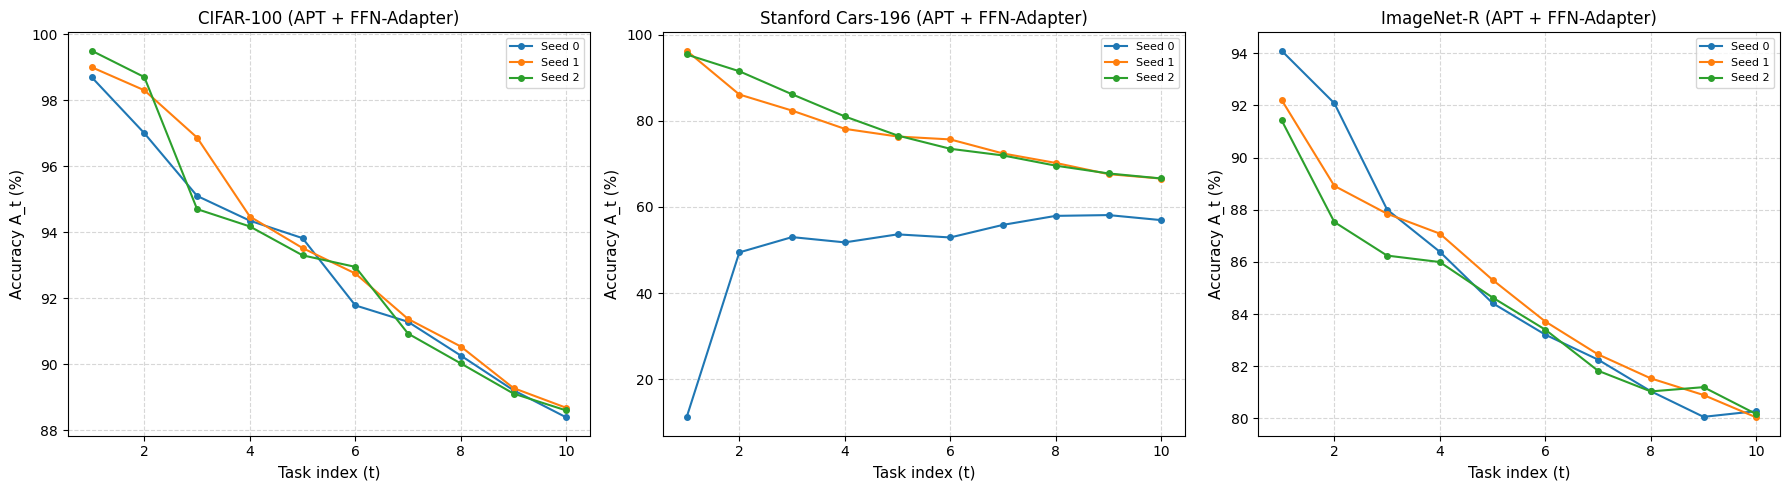

In [8]:
import matplotlib.pyplot as plt

master_rows = []

for ds_key, ds_results in ALL_RESULTS.items():
    ds_name = DATASET_CONFIGS[ds_key]["name"]
    for k, r in ds_results.items():
        comp = r.get("complexity", {})
        master_rows.append({
            "Dataset": ds_name,
            "Experiment": k,
            "Trainable (M)": round(comp.get("n_trainable", 0) / 1e6, 3),
            "GFLOPs": comp.get("gflops", 16.86),
            "Phase": r.get("phase", "val").upper(),
            "Seed": r.get("seed", 0),
            "Last Acc (%)": round(r.get("last", 0.0), 2),
            "Avg Acc (%)": round(r.get("avg", 0.0), 2),
            "Forgetting (%)": round(r.get("forgetting", 0.0), 2)
        })

df_all = pd.DataFrame(master_rows)
if not df_all.empty:
    print("📋 BẢNG KẾT QUẢ CHI TIẾT TỪNG SEED (KÈM PARAMS & FLOPS):", flush=True)
    display(df_all)
    df_all.to_csv(os.path.join(GLOBAL_CFG["base_out_dir"], "master_adapter_ppf_detailed.csv"), index=False)

    print("\n🏆 BẢNG MASTER: SO SÁNH HIỆU NĂNG APT + FFN-ADAPTER (PPF) QUA CÁC DATASET (MEAN ± STD):", flush=True)
    master_stats = df_all.groupby(["Dataset", "Phase"]).agg({
        "Trainable (M)": "first",
        "GFLOPs": "first",
        "Last Acc (%)": ["mean", "std"],
        "Avg Acc (%)": ["mean", "std"],
        "Forgetting (%)": ["mean", "std"]
    }).round(2)
    display(master_stats)
    master_stats.to_csv(os.path.join(GLOBAL_CFG["base_out_dir"], "master_adapter_ppf_mean_std.csv"))

    # Vẽ biểu đồ so sánh đường cong A_t giữa các dataset
    n_datasets = len(ALL_RESULTS)
    fig, axes = plt.subplots(1, n_datasets, figsize=(6 * n_datasets, 5), squeeze=False)
    
    for i, (ds_key, ds_results) in enumerate(ALL_RESULTS.items()):
        ax = axes[0, i]
        ds_name = DATASET_CONFIGS[ds_key]["name"]
        for k, r in ds_results.items():
            a_t = r.get("A_t", [])
            if a_t:
                ax.plot(range(1, len(a_t) + 1), a_t, marker="o", markersize=4, label=f"Seed {r.get('seed')}")
        ax.set_xlabel("Task index (t)", fontsize=11)
        ax.set_ylabel("Accuracy A_t (%)", fontsize=11)
        ax.set_title(f"{ds_name} (APT + FFN-Adapter)", fontsize=12)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend(loc="best", fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(GLOBAL_CFG["base_out_dir"], "multi_dataset_adapter_ppf_curves.png"), dpi=150)
    plt.show()